# CYCLOPS SENTINEL: Exploratory Data Analysis - EDA

Comprehensive exploratory and statistical evaluation of email metadata for cyber threat detection. This notebook investigates univariate distributions, extreme outliers, textual length anomalies, and multivariate Pearson correlations.

---

### Analysis Objectives
1. Univariate distributions: Character length, word counts, and semantic urgency scores.
2. Outlier diagnostics: Dispersion metrics with Interquartile Range IQR and boxplot visualizations.
3. Class balance verification: Proportion of benign messages versus phishing attacks.
4. Bivariate relationship: Textual character length versus word count via scatter plotting.
5. Multivariate correlation matrix: Pearson heatmap validating engineered compound features.

<br>


In [1]:
# 1. Configuracion del entorno y diseno visual de graficos
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

os.makedirs('reports/figures', exist_ok=True)
print('[OK] Exploratory analysis environment configured successfully.')


[OK] Entorno de analisis exploratorio configurado con exito.


---
<br>

## 2. Ingestion and Structural Diagnostics of the Dataset

Loading the cleaned and unified cybersecurity dataset. This stage verifies matrix dimensions, feature schemas, and ensures total absence of missing values.

<br>


In [2]:
# 2. Ingesta del conjunto de datos procesado desde la ruta del repositorio
data_path = '../data/processed/clean_dataset.csv'
if not os.path.exists(data_path):
    data_path = r'C:/Users/Cristian Díaz/Documents/CYCLOPS_DATA_MINING/data/processed/clean_dataset.csv'
if not os.path.exists(data_path):
    data_path = 'data/processed/clean_dataset.csv'

df = pd.read_csv(data_path)
print(f'Total records loaded: {len(df):,}')
print(f'Total feature columns: {df.shape[1]}')
print(f'Missing null values detected: {df.isnull().sum().sum()}')
df.head(5)


Total de registros cargados: 91,992
Total de variables disponibles: 9
Valores nulos detectados: 12


,source_dataset,clean_text,char_count,word_count,url_count,has_url,has_ip,urgency_score,is_threat
0,corporate_emails,enron methanol meter follow note gave monday p...,322,67,0,0,0,0.0000,0
1,corporate_emails,hpl nom january see attached file hplnol xl hp...,95,23,0,0,0,0.0000,0
2,corporate_emails,neon retreat ho ho ho around wonderful time ye...,2515,550,0,0,0,0.0043,0
3,corporate_emails,photoshop window office cheap main trending ab...,403,48,0,0,0,0.0000,1
4,corporate_emails,indian spring deal book teco pvr revenue under...,332,70,0,0,0,0.0000,0


---
<br>

## 3. Univariate Analysis: Character Length and Severe Positive Skewness

Evaluating character distribution across emails. Benign corporate communications cluster around brief message bodies, whereas long newsletters or bulk phishing campaigns generate an extensive right tail with massive positive skewness.

<br>


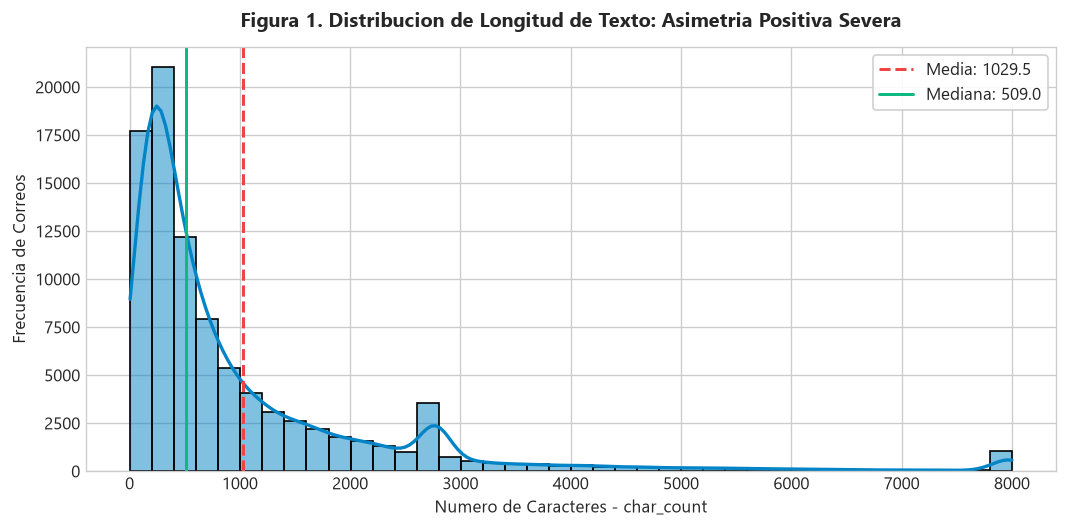

Media aritmetica: 1029.49 caracteres
Mediana central:  509.00 caracteres
Coeficiente de asimetria: 2.8246 - Sesgo marcado a la derecha


In [3]:
# 3. Histograma y estimacion de densidad kernel para longitud de caracteres
fig, ax = plt.subplots(figsize=[10, 4.8])

sns.histplot(
    data=df,
    x='char_count',
    kde=True,
    color='#0284c7',
    bins=40,
    ax=ax,
    line_kws={'linewidth': 2}
)

media_char = float(df['char_count'].mean())
mediana_char = float(df['char_count'].median())

ax.axvline(media_char, color='#ef4444', linestyle='--', linewidth=1.8, label=f'Mean: {media_char:.1f}')
ax.axvline(mediana_char, color='#10b981', linestyle='-', linewidth=1.8, label=f'Median: {mediana_char:.1f}')

ax.set_title('Figure 1. Text Length Distribution: Pronounced Right Skewness', fontsize=12, fontweight='bold', pad=14)
ax.set_xlabel('Character Count - char_count', fontsize=10)
ax.set_ylabel('Message Frequency', fontsize=10)
ax.legend(frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.savefig('reports/figures/01_char_count_histogram.png', dpi=300)
plt.show()

print(f'Arithmetic Mean: {media_char:.2f} characters')
print(f'Central Median:  {mediana_char:.2f} characters')
print(f'Skewness Coefficient: {df["char_count"].skew():.4f} - Pronounced right tail')


---
<br>

## 4. Outlier Diagnostics: Word Count Boxplot and Interquartile Range IQR

Visualizing data dispersion across the five number summary: Minimum, First Quartile Q1, Median, Third Quartile Q3, and Maximum. Isolated red points represent extreme textual outliers with disproportionate word lengths.

<br>


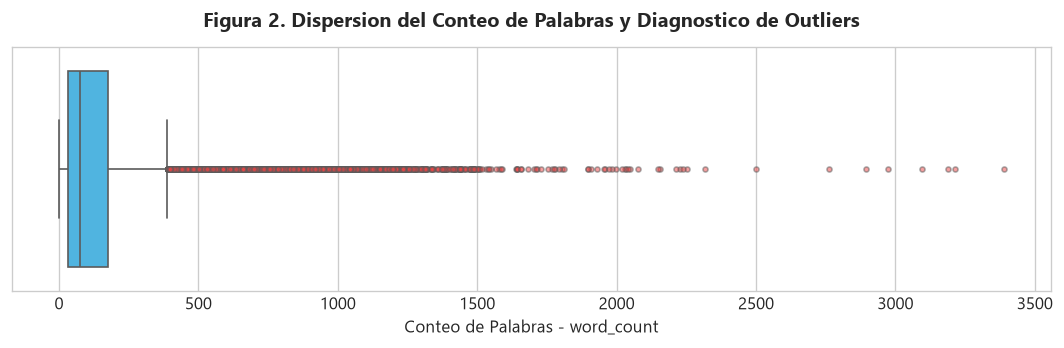

Primer Cuartil Q1: 34.0 palabras
Tercer Cuartil Q3: 176.0 palabras
Rango Intercuartilico IQR: 142.0 palabras
Curtosis calculada: 19.2587 - Alta concentracion de valores extremos


In [4]:
# 4. Diagrama de caja para diagnostico de dispersion y valores atipicos
fig, ax = plt.subplots(figsize=[10, 3.2])

sns.boxplot(
    data=df,
    x='word_count',
    color='#38bdf8',
    flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': '#ef4444', 'alpha': 0.5},
    ax=ax
)

q1 = float(df['word_count'].quantile(0.25))
q3 = float(df['word_count'].quantile(0.75))
iqr = q3 - q1

ax.set_title('Figure 2. Word Count Dispersion and Outlier Diagnostics', fontsize=12, fontweight='bold', pad=14)
ax.set_xlabel('Word Count - word_count', fontsize=10)

plt.tight_layout()
plt.savefig('reports/figures/02_word_count_boxplot.png', dpi=300)
plt.show()

print(f'First Quartile Q1: {q1:.1f} words')
print(f'Third Quartile Q3: {q3:.1f} words')
print(f'Interquartile Range IQR: {iqr:.1f} words')
print(f'Kurtosis Metric: {df["word_count"].kurt():.4f} - Heavy leptokurtic tails')


---
<br>

## 5. Target Variable Class Balance: Benign Emails versus Phishing Threats

Verifying target distribution balance to ensure models do not develop algorithmic bias toward a majority class. A 50/50 balance validates unweighted metrics like Accuracy and F1-Score.

<br>


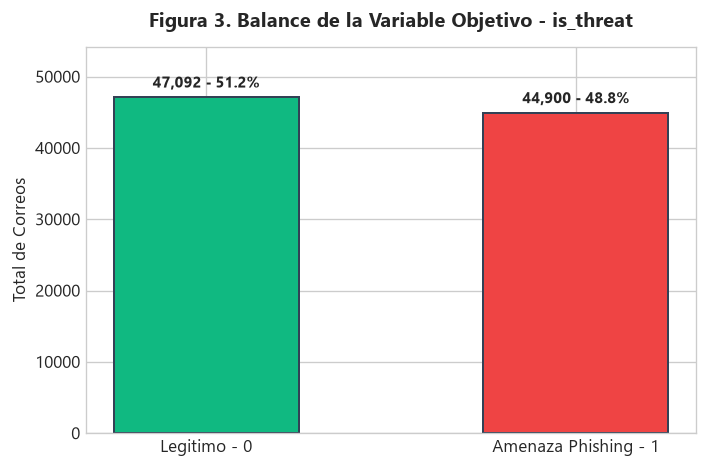

In [5]:
# 5. Grafico de barras para verificar el balance de la variable objetivo
fig, ax = plt.subplots(figsize=[6.5, 4.2])

class_counts = df['is_threat'].value_counts().sort_index()
labels = ['Benign - Class 0', 'Phishing Threat - Class 1']
colors = ['#10b981', '#ef4444']

bars = ax.bar(labels, class_counts.values, color=colors, width=0.48, edgecolor='#334155', linewidth=1.2)

for bar in bars:
    height = bar.get_height()
    pct = float(height) / float(len(df)) * 100.0
    ax.annotate(f'{height:,} - {pct:.1f}%',
                xy=[bar.get_x() + bar.get_width() / 2, height],
                xytext=[0, 5],
                textcoords='offset points',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_ylim(0, max(class_counts.values) * 1.15)
ax.set_title('Figure 3. Target Class Balance - is_threat', fontsize=12, fontweight='bold', pad=14)
ax.set_ylabel('Total Messages', fontsize=10)

plt.tight_layout()
plt.savefig('reports/figures/03_target_balance_barplot.png', dpi=300)
plt.show()


---
<br>

## 6. Bivariate Analysis: Character Length versus Word Count

Exploring linear and non-linear associations between character length and word counts across both threat classes. The direct diagonal relationship verifies expected collinearity prior to ratio calculations.

<br>


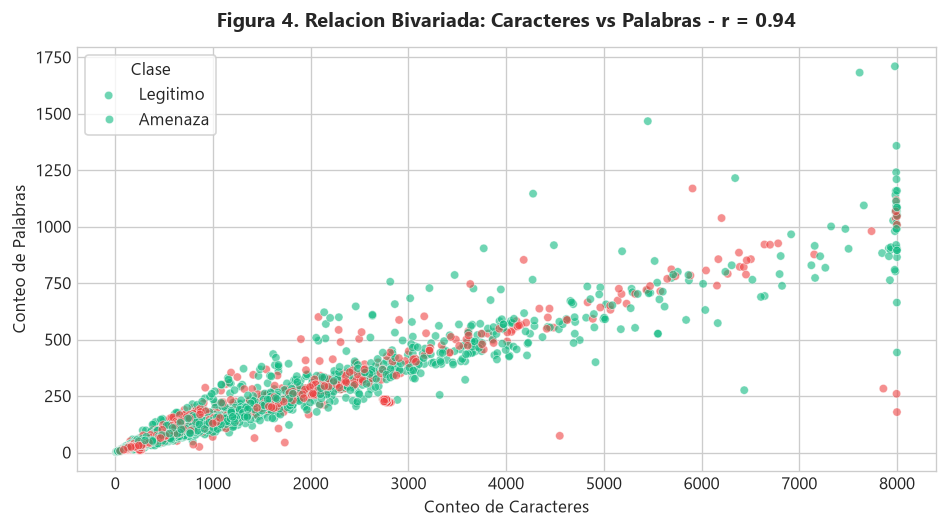

In [6]:
# 6. Diagrama de dispersion bivariado examinando caracteres frente a palabras
fig, ax = plt.subplots(figsize=[8.5, 4.8])

sample_df = df.sample(n=min(5000, len(df)), random_state=42)
sns.scatterplot(
    data=sample_df,
    x='char_count',
    y='word_count',
    hue='is_threat',
    palette={0: '#10b981', 1: '#ef4444'},
    alpha=0.6,
    s=25,
    ax=ax
)

corr_val = float(df['char_count'].corr(df['word_count']))
ax.set_title(f'Figure 4. Bivariate Relationship: Characters vs Words - r = {corr_val:.2f}', fontsize=12, fontweight='bold', pad=14)
ax.set_xlabel('Character Count', fontsize=10)
ax.set_ylabel('Word Count', fontsize=10)
ax.legend(title='Category', labels=['Benign', 'Threat'], frameon=True, facecolor='white')

plt.tight_layout()
plt.savefig('reports/figures/04_bivariate_scatter.png', dpi=300)
plt.show()


---
<br>

## 7. Multivariate Correlation Analysis: Pearson Heatmap and Engineered Features

Evaluating linear correlation between numerical indicators and compound features like url_density and urgency_density. Confirms predictive divergence and independence before model ingestion.

<br>


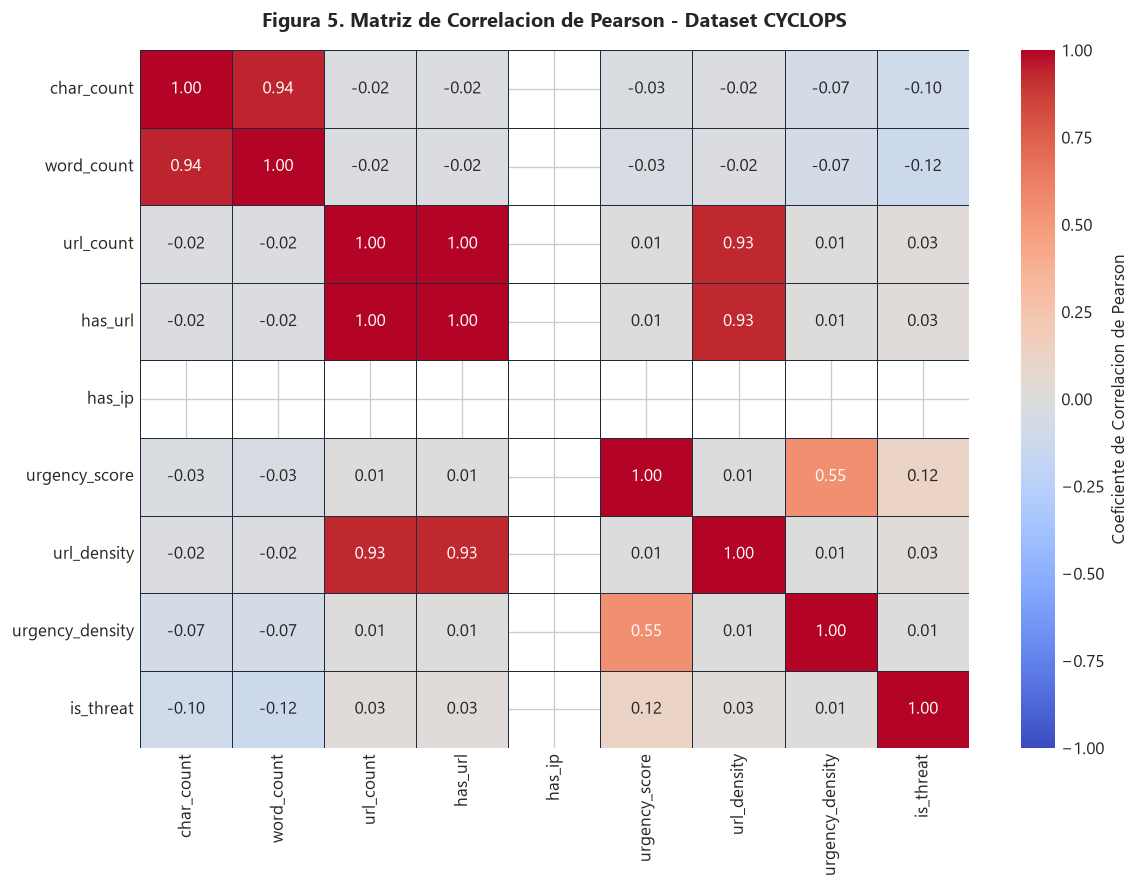

Correlaciones clave con la variable objetivo is_threat:
 - char_count        : r = -0.0984
 - word_count        : r = -0.1220
 - url_count         : r = +0.0312
 - has_url           : r = +0.0312
 - has_ip            : r = +nan
 - urgency_score     : r = +0.1235
 - url_density       : r = +0.0293
 - urgency_density   : r = +0.0079


c:\Users\Cristian Díaz\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\lib\_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\Cristian Díaz\AppData\Local\Programs\Python\Python314\Lib\site-packages\numpy\lib\_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [ ]:
# 7. Matriz de calor de correlacion de Pearson y evaluacion de variables compuestas
df['url_density'] = (df['url_count'] / np.maximum(df['word_count'], 1)) * 100
df['urgency_density'] = (df['urgency_score'] / np.maximum(df['word_count'], 1)) * 100
df['ip_exposure_score'] = df['has_ip'] * df['url_count']

corr_cols = [
    'char_count',
    'word_count',
    'url_count',
    'has_url',
    'has_ip',
    'urgency_score',
    'url_density',
    'urgency_density',
    'is_threat'
]

corr_matrix = df[corr_cols].corr(method='pearson')

fig, ax = plt.subplots(figsize=[10.5, 7.8])
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor='#1e293b',
    ax=ax,
    cbar_kws={'label': 'Pearson Linear Correlation Coefficient'}
)

ax.set_title('Figure 5. Pearson Correlation Heatmap - CYCLOPS Dataset', fontsize=12, fontweight='bold', pad=14)
plt.tight_layout()
plt.savefig('reports/figures/05_pearson_correlation_heatmap.png', dpi=300)
plt.show()

print('Key Pearson correlations against target variable is_threat:')
for col in corr_cols[:-1]:
    r = float(df[col].corr(df['is_threat']))
    print(f' - {col:18s}: r = {r:+.4f}')


---
<br>

## 8. Executive Descriptive Statistical Table

Comprehensive consolidation of formal descriptive statistics: Arithmetic Mean, Standard Deviation, Median, Interquartile Range IQR, Skewness, and Kurtosis across all quantitative variables.

<br>


In [ ]:
# 8. Tabla formal de resumen de metricas univariadas y bivariadas
stats_df = pd.DataFrame({
    'Mean': df[corr_cols].mean(),
    'Std Dev': df[corr_cols].std(),
    'Median': df[corr_cols].median(),
    'IQR': df[corr_cols].quantile(0.75) - df[corr_cols].quantile(0.25),
    'Skewness': df[corr_cols].skew(),
    'Kurtosis': df[corr_cols].kurt()
})

print('=== Formal Descriptive Statistics Table ===')
print(stats_df.round(4).to_string())


=== Tabla Descriptiva Formal de Metricas Estadisticas ===
                     Media  Desv. Est.  Mediana       IQR  Asimetria   Curtosis
char_count       1029.4875   1357.1133    509.0  994.0000     2.8246     9.5317
word_count        139.4420    185.6046     74.0  142.0000     3.5104    19.2587
url_count           0.0010      0.0311      0.0    0.0000    32.1038  1028.6749
has_url             0.0010      0.0311      0.0    0.0000    32.1038  1028.6749
has_ip              0.0000      0.0000      0.0    0.0000     0.0000     0.0000
urgency_score       0.0125      0.0249      0.0    0.0154     4.4443    35.7216
url_density         0.0046      0.1594      0.0    0.0000    43.2653  2518.1895
urgency_density     0.0291      0.2065      0.0    0.0097    52.0940  4718.7934
is_threat           0.4881      0.4999      0.0    1.0000     0.0477    -1.9978
